In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier

from sklearn.metrics import accuracy_score
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import f1_score
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix

In [ ]:
bank_datasett = pd.read_csv("../data/bank/bank-full.csv", sep=";")
bank_datasett.columns = [
    "age",
    "job",
    "marital",
    "education",
    "default",
    "balance",
    "housing",
    "loan",
    "contact",
    "day",
    "month",
    "duration",
    "campaign",
    "pdays",
    "previous",
    "poutcome",
    "y",
]

bank_datasett.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


In [ ]:
#show the data types and non-null counts of each column
bank_datasett.info()

<class 'pandas.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   age        45211 non-null  int64
 1   job        45211 non-null  str  
 2   marital    45211 non-null  str  
 3   education  45211 non-null  str  
 4   default    45211 non-null  str  
 5   balance    45211 non-null  int64
 6   housing    45211 non-null  str  
 7   loan       45211 non-null  str  
 8   contact    45211 non-null  str  
 9   day        45211 non-null  int64
 10  month      45211 non-null  str  
 11  duration   45211 non-null  int64
 12  campaign   45211 non-null  int64
 13  pdays      45211 non-null  int64
 14  previous   45211 non-null  int64
 15  poutcome   45211 non-null  str  
 16  y          45211 non-null  str  
dtypes: int64(7), str(10)
memory usage: 5.9 MB


In [ ]:
#Investigate the number of unique values in each column
print(bank_datasett.nunique())

age            77
job            12
marital         3
education       4
default         2
balance      7168
housing         2
loan            2
contact         3
day            31
month          12
duration     1573
campaign       48
pdays         559
previous       41
poutcome        4
y               2
dtype: int64


In [ ]:
#Check for missing values in the dataset
print(bank_datasett.isnull().sum())

age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
pdays        0
previous     0
poutcome     0
y            0
dtype: int64


In [ ]:
#Check for duplicate rows in the dataset
print(bank_datasett.duplicated().sum())

0


In [ ]:
#Drop duration to avoid data leakage
bank_datasett = bank_datasett.drop('duration', axis=1)
bank_datasett.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,1,-1,0,unknown,no


In [ ]:
stats = bank_datasett.describe()

In [ ]:
# Calculate the interquartile range (IQR) for numerical columns (Q3 - Q1)
IQR = stats.loc['75%'] - stats.loc['25%']
IQR

age           15.0
balance     1356.0
day           13.0
campaign       2.0
pdays          0.0
previous       0.0
dtype: float64

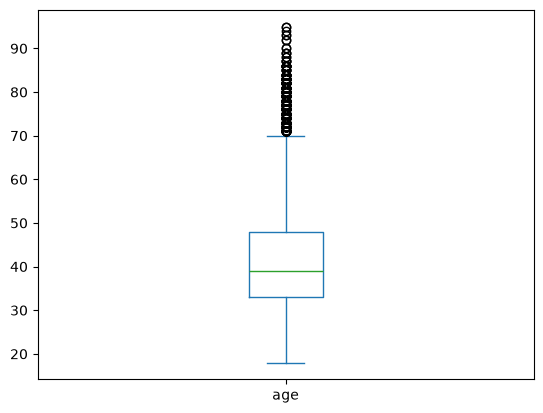

In [ ]:
#visualize potiential outliers in the 'age' column using a boxplot
bank_datasett['age'].plot.box()
plt.show()

In [ ]:
#cheking the minimum value of the 'age' column to identify potential outliers
bank_datasett['age'].min()

np.int64(18)

In [ ]:
#checking the maximum value of the 'age' column to identify potential outliers
bank_datasett['age'].max()

#Age has outliners above abroximately 70 years old.
#The minimum age is 18 years old, and the maximum age is 95 years old.
#these values are realistic, so outliners are kept in the dataset.

np.int64(95)

In [ ]:
#Investigate the target variable 'y' to understand the distribution of the classes
bank_datasett['y'].value_counts()
bank_datasett['y'].value_counts(normalize=True) * 100

y
no     88.30152
yes    11.69848
Name: proportion, dtype: float64

### Target Distribution

The target variable is imbalanced. Approximately 88.3% of the customers did not subscribe to a term deposite, while 11.7% did subscribe. Beacuse of this imbalnce, accuracy alone may not be sufficient when evaluating the models. Precision , recall and F1-score will also be important. 

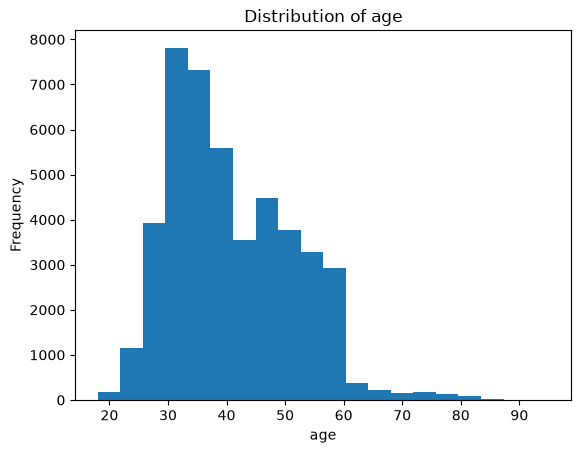

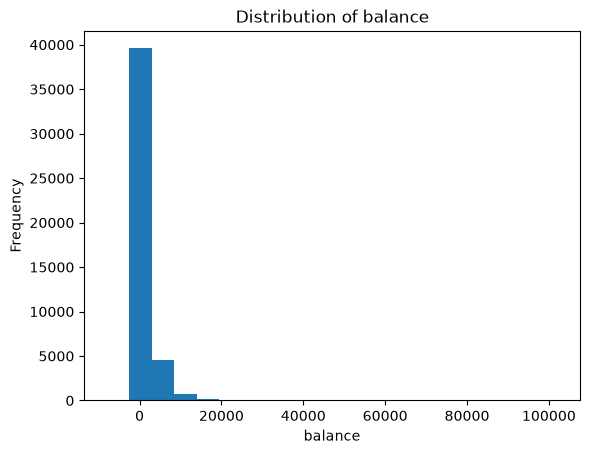

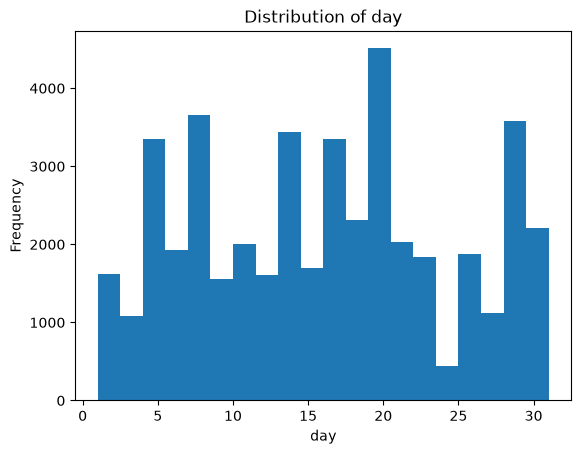

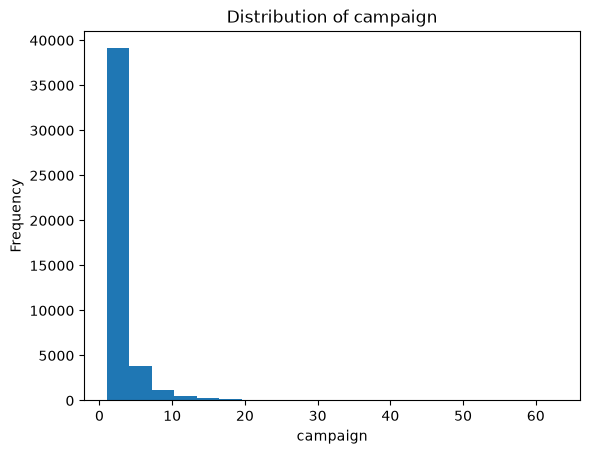

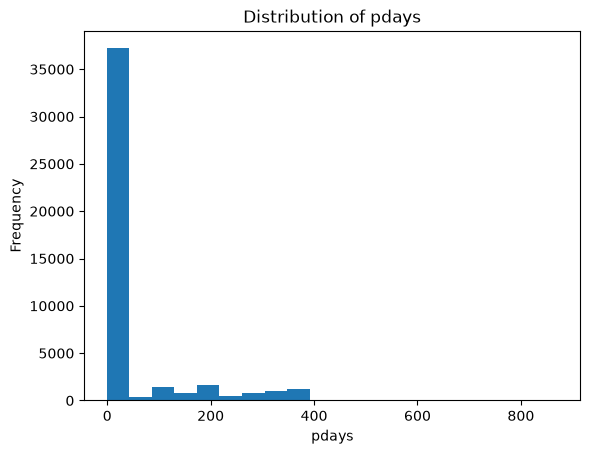

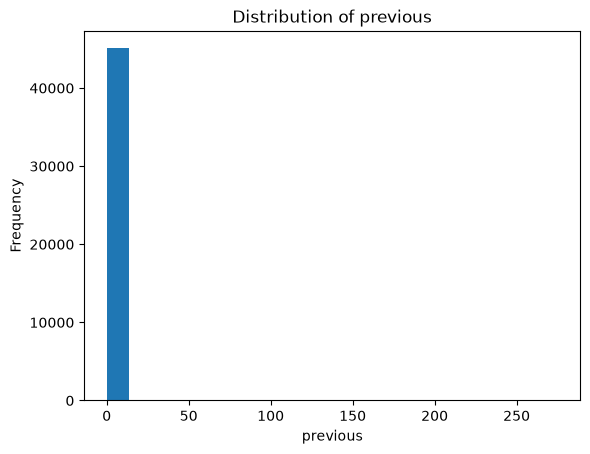

In [ ]:
numerical_columns = [
    'age',
    'balance',
    'day',
    'campaign',
    'pdays',
    'previous'
]
for column in numerical_columns:
    bank_datasett[column].plot.hist(bins=20)
    plt.xlabel(column)
    plt.ylabel('Frequency')
    plt.title(f'Distribution of {column}')
    plt.show()

/var/folders/zd/n974tjhs1k39sytwhct8t8fc0000gn/T/ipykernel_34636/1399147490.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = bank_datasett.select_dtypes(include='object').columns


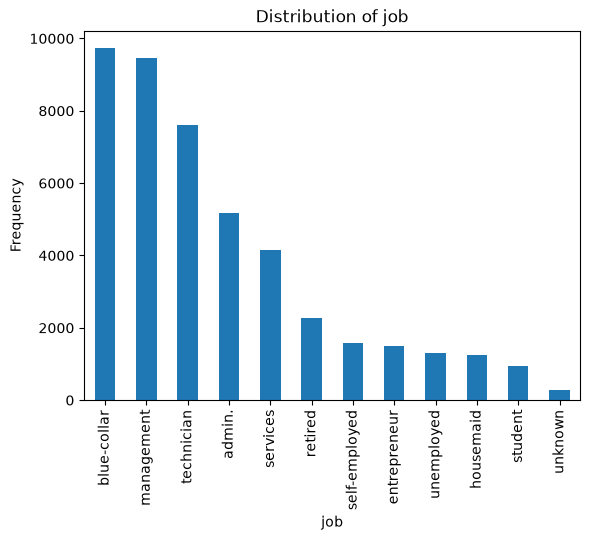

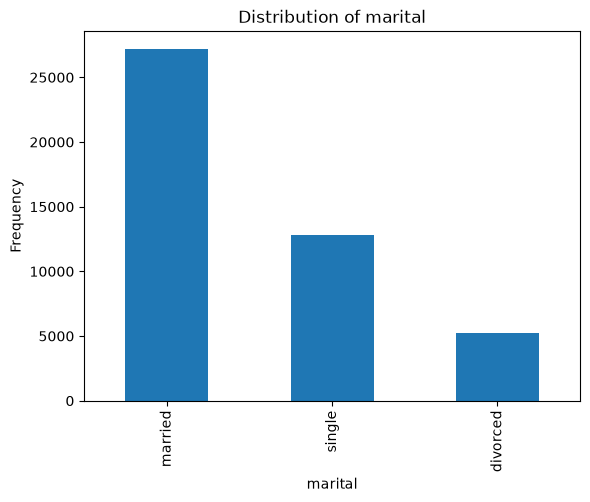

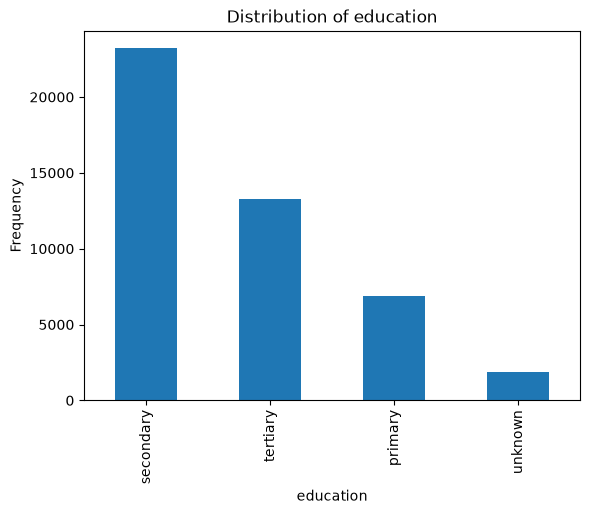

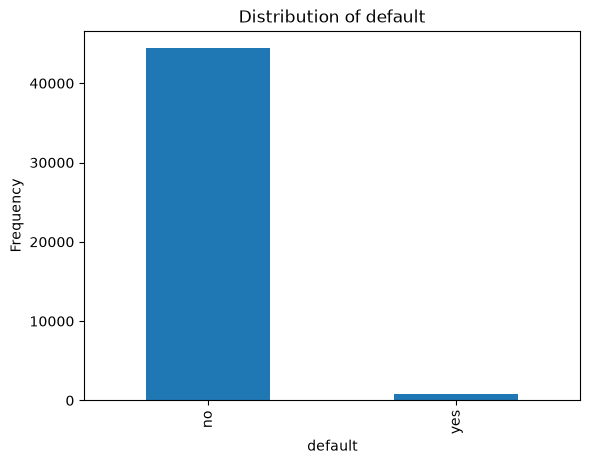

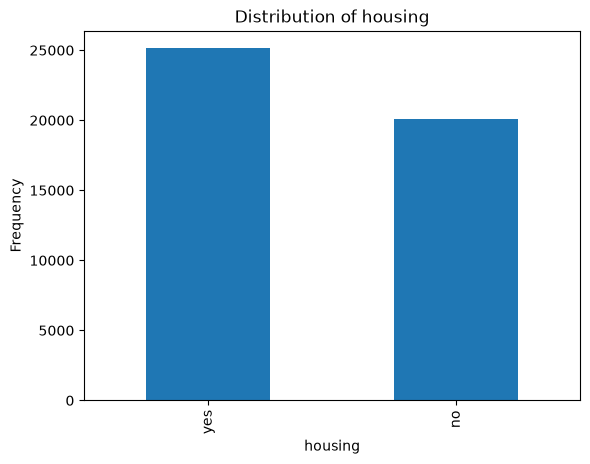

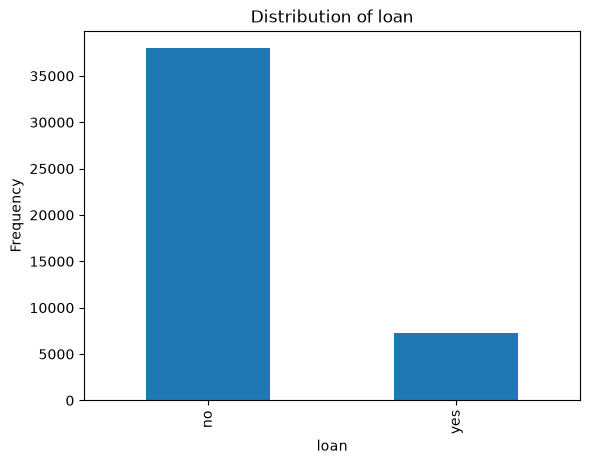

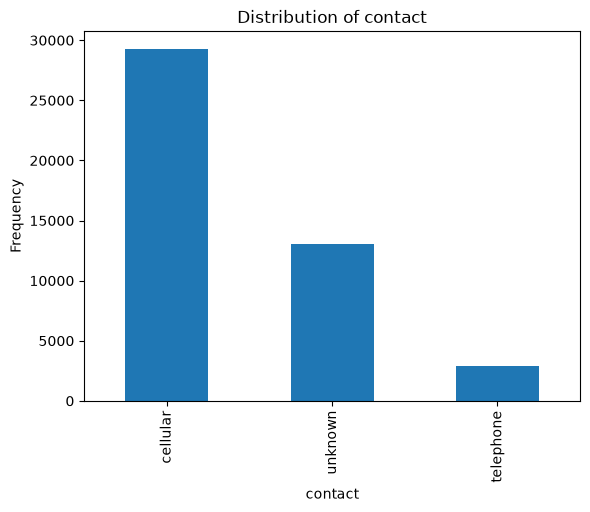

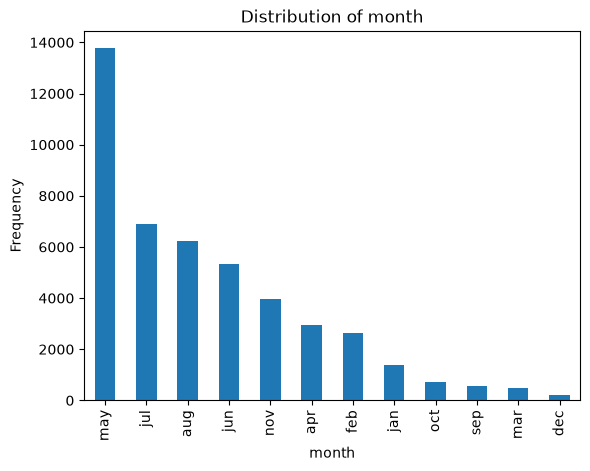

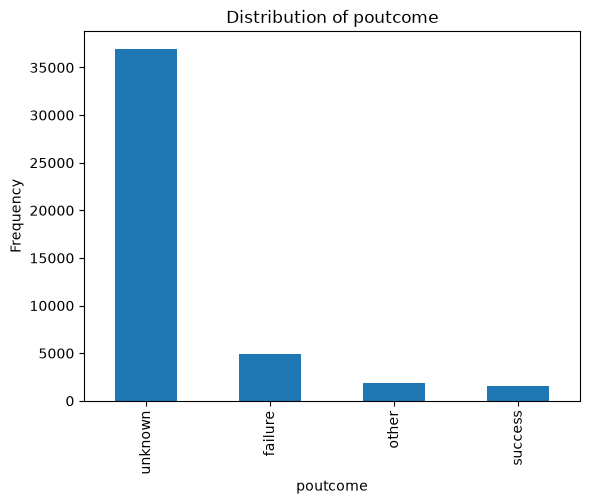

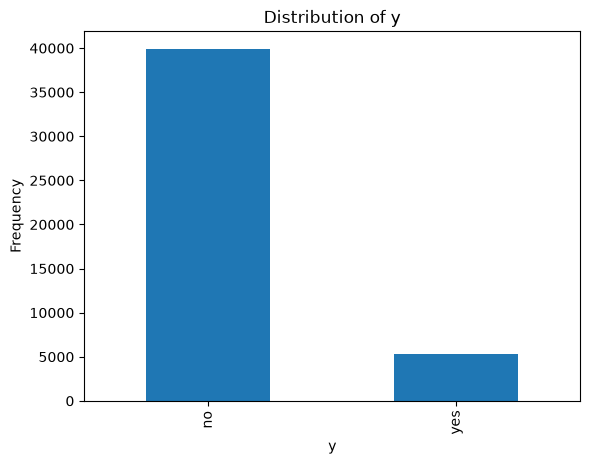

In [ ]:
categorical_columns = bank_datasett.select_dtypes(include='object').columns

for column in categorical_columns:
    bank_datasett[column].value_counts().plot.bar()
    plt.xlabel(column)
    plt.ylabel('Frequency')
    plt.title(f'Distribution of {column}')
    plt.show()

In [ ]:
categorical_columns = bank_datasett.select_dtypes(include='object').columns

for column in categorical_columns:
    if column != 'y':
        relationship = pd.crosstab(
            bank_datasett[column],
            bank_datasett['y'],
            normalize='index'
        ) * 100

        print(f"\n{column}")
        print(relationship)


job
y                     no        yes
job                                
admin.         87.797331  12.202669
blue-collar    92.725031   7.274969
entrepreneur   91.728312   8.271688
housemaid      91.209677   8.790323
management     86.244449  13.755551
retired        77.208481  22.791519
self-employed  88.157061  11.842939
services       91.116996   8.883004
student        71.321962  28.678038
technician     88.943004  11.056996
unemployed     84.497314  15.502686
unknown        88.194444  11.805556

marital
y                no        yes
marital                       
divorced  88.054542  11.945458
married   89.876534  10.123466
single    85.050821  14.949179

education
y                 no        yes
education                      
primary    91.373522   8.626478
secondary  89.440565  10.559435
tertiary   84.993610  15.006390
unknown    86.429725  13.570275

default
y               no        yes
default                      
no       88.203892  11.796108
yes      93.619632   6.38

/var/folders/zd/n974tjhs1k39sytwhct8t8fc0000gn/T/ipykernel_34636/192809884.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = bank_datasett.select_dtypes(include='object').columns


Categorical relationships: Serval categorical features show diffrince in subscription rates. Job appears to have relationship with the target, with students and retired customers having higher subscription rates. The strongest diffrince is observed for poutcome, where customers with previous succsful campaign outcome have a substantially higher subscription rate. 

### Correlation HeatMap

A correlation heatmap is used to visualize the relationships between numerical features in the dataset. 

It helps identify features that strongly positively or negatively correlated

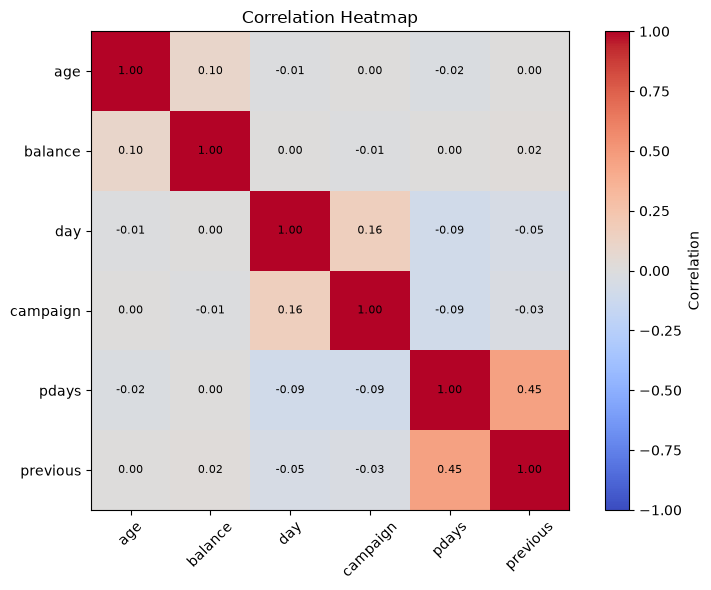

In [ ]:
#Select numrical features
numerical_data = bank_datasett.select_dtypes(include='number')

#Calculate the correlation
correlation_matrix = numerical_data.corr()

#Create correlation heatmap
plt.figure(figsize=(8, 6))
plt.imshow(correlation_matrix, cmap='coolwarm', vmin=-1, vmax=1)

plt.colorbar(label='Correlation')

plt.xticks(
    range(len(correlation_matrix.columns)),
    correlation_matrix.columns,
    rotation=45,
)

plt.yticks(
    range(len(correlation_matrix.columns)),
    correlation_matrix.columns,
)

plt.title('Correlation Heatmap')
plt.tight_layout()
for i in range(len(correlation_matrix.columns)):
    for j in range(len(correlation_matrix.columns)):
        plt.text(
            j,
            i,
            f"{correlation_matrix.iloc[i, j]:.2f}",
            ha='center',
            va='center',
            fontsize=8,
        )
plt.show()

### Correlation Heatmap Resultes 

This correlation heatmap shows that most numerical features have weak correlation with each other.

The strongest correlation is between pdays and previous (0.45), indicating a modrate positive relationship.

Day and campaign have a weak positive correlation of 0.16, while age and balance have a weak postive correlation of 0.10. 

Overall, most numerical features do not show strong linear realtionship.

## Data Processing

Before training the models, the data needs to be prepared. The target variable 'y' is spreated from the features and converted from 'no' and 'yes' to 0 and 1. 

In [ ]:
#Spreate the features from the target variable
X = bank_datasett.drop('y', axis=1)
y = bank_datasett['y']

# Encode the target variable: no = 0, yes = 1
y = y.map({
    'no': 0,
    'yes': 1
})

#Check the result
print(y.value_counts())

y
0    39922
1     5289
Name: count, dtype: int64


### Categories Features

The dataset contains categorical features that need to be into numerical values before they can be used by machine learning modelles

In [ ]:
#Chek which features are categorical
categorical_features = X.select_dtypes(include='object').columns

print(categorical_features)

Index(['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact',
       'month', 'poutcome'],
      dtype='str')


/var/folders/zd/n974tjhs1k39sytwhct8t8fc0000gn/T/ipykernel_34636/319643982.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X.select_dtypes(include='object').columns


### One-hot Encoding

Categorical feature need to be converted into numerical values before traning the models

One-hot endcoding will be preformed after spliting the dataset to avoid data leakage.

In [ ]:
#Encoding will be fitted to the training data after splitting.
X.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,campaign,pdays,previous,poutcome
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,1,-1,0,unknown
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,1,-1,0,unknown
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,1,-1,0,unknown
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,1,-1,0,unknown
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,1,-1,0,unknown


### Traning, Validation and Test Split

The dataset is divided into training, validation and test sets. 60% is used for traning, 20% for validation, 20% for testing. Stratification is used to maintain approximately the same class distribution in each set.

In [ ]:
#Split the data sett into a 60% taining and 40% temprorary data
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.4,
    random_state=13,
    stratify=y
)

#split the temproray data into 20% validation and 20% test data
X_validation , X_test, y_validation, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.5,
    random_state=13,
    stratify=y_temp
)

# One-hot encoding 
X_train = pd.get_dummies(
    X_train,
    columns=categorical_features,
)

X_validation = pd.get_dummies(
    X_validation,
    columns=categorical_features,
)

X_test = pd.get_dummies(
    X_test,
    columns=categorical_features,
)

#Ensure all datasets have the same clumns 
X_validation = X_validation.reindex(
    columns=X_train.columns, 
    fill_value=0
)
X_test = X_test.reindex(
    columns=X_train.columns, 
    fill_value=0
)

In [ ]:
#Check the size of each dataset
print("Training:", X_train.shape)
print("Validation:", X_validation.shape)
print("Test:", X_test.shape)

Training: (27126, 50)
Validation: (9042, 50)
Test: (9043, 50)


In [ ]:
#Check the class distribution in each dataset
print("Training:")
print(y_train.value_counts(normalize=True) * 100)

print("\nValidation:")
print(y_validation.value_counts(normalize=True) * 100)

print("\nTest:")
print(y_test.value_counts(normalize=True) * 100)

Training:
y
0    88.302735
1    11.697265
Name: proportion, dtype: float64

Validation:
y
0    88.299049
1    11.700951
Name: proportion, dtype: float64

Test:
y
0    88.300343
1    11.699657
Name: proportion, dtype: float64


The dataset was successfully split into 60% training data, 20% valdtion data and 20% test data. Each dataset contains 50 features after one-hot ecoding.

### Baseline models

Three baseline classification models will be trained and evaluated. The models are trained using the traning dataset and initially evaluated using validation dataset. 

### Decision Tree 

The first baseline mode is a Decision Tree classifier. The model first trained using the default hyperparameters to provide a baseline result before manual hyperparameter tuning.

In [ ]:
#Creat a Decision Tree model with deafult hyperparameters
decision_tree = DecisionTreeClassifier(random_state=13)

#Train the model on the training data
decision_tree.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",13
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples

In [ ]:
# Make predictions on the validation data
y_validation_pred = decision_tree.predict(X_validation)

# Evaluate the Decision Tree
print("Accuracy:", accuracy_score(y_validation, y_validation_pred))
print("Precision:", precision_score(y_validation, y_validation_pred))
print("Recall:", recall_score(y_validation, y_validation_pred))
print("F1 Score:", f1_score(y_validation, y_validation_pred))


Accuracy: 0.83178500331785
Precision: 0.2942222222222222
Recall: 0.31285444234404536
F1 Score: 0.3032524049473202


The baseline Decision Tree achieved an accuracy of approximately 83.2%. However, the precision, recall and F1-score are considerably lower at 29.4%, 31.3% and 30.3, this indcates thats accuracy alone dose not give a complete picture of the model´s preformance, especially beacuse the dataset is imbalanced.

### Gaussian Naive Bayes

The second baseline model is a Gaussian Naive Bayes, The model is trained using training data with it deafult hyperparmeteres and evaluated using the validation data.

In [ ]:
#Create a Gaussian Naive Bayes model
naive_bayes = GaussianNB()

#Train the model using the training data
naive_bayes.fit(X_train, y_train)

,"priors priors: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
,"var_smoothing var_smoothing: float, default=1e-9Portion of the largest variance of all features that is added tovariances for calculation stability... versionadded:: 0.20",1e-09
Name,Type,Value
"class_count_ class_count_: ndarray of shape (n_classes,)number of training samples observed in each class.","ndarray[float64](2,)","[23953., 3173.]"
"class_prior_ class_prior_: ndarray of shape (n_classes,)probability of each class.","ndarray[float64](2,)","[0.88,0.12]"
"classes_ classes_: ndarray of shape (n_classes,)class labels known to the classifier.","ndarray[int64](2,)","[0,1]"
epsilon_ epsilon_: floatabsolute additive value to variances.,float64,0.009056
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](50,)","['age','balance','day',...,'poutcome_other','poutcome_success', 'poutcome_unknown']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,50
"theta_ theta_: ndarray of shape (n_classes, n_features)mean of each feature per class.","ndarray[float64](2, 50)","[[ 40.82,1305.8 , 15.86,..., 0.04, 0.01, 0.84], [ 41.91,1805.98, 15.11,..., 0.06, 0.18, 0.65]]"
"var_ var_: ndarray of shape (n_classes, n_features)Variance of each feature per class... versionadded:: 1.0","ndarray[float64](2, 50)","[[ 103.95, 8649181.75, 68.73,..., 0.05, 0.02, 0.14], [ 183.72,11903628.81, 72.03,..., 0.06, 0.16, 0.24]]"


In [ ]:
#Make predictions on the validation data
y_validation_pred_nb = naive_bayes.predict(X_validation)

#Evaluate the Gaussian Naive Bayes model
print("Accuracy:", accuracy_score(y_validation, y_validation_pred_nb))
print("Precision:", precision_score(y_validation, y_validation_pred_nb))
print("Recall:", recall_score(y_validation, y_validation_pred_nb))
print("F1 Score:", f1_score(y_validation, y_validation_pred_nb))

Accuracy: 0.8388630833886308
Precision: 0.36269786648313834
Recall: 0.498109640831758
F1 Score: 0.41975308641975306


The baseline Gaussian Naive Bayes model achieved an accuracy of 83.9%, a precision of 36.3%, reacall of 49.8% and an F1-score of 42.0%. Compared with the baseline Decision Tree, Gussian Naive Bayes achieved a higher validation score, especially for recall and F1-score

### Feature Scaling

Logistic Regression produced a convergence warning beacuse the numrical features have different scales. StandardScaler is used to scale the features before training the Logistic Regression model. The scaler is fitted only on the tranining data to avoid data leakage. 

### Logistic Regression

The third baseline model is Logistic Regression. The model is trained using the training data and evaluted using the validation data.

In [ ]:
# Creat the scaler
scaler = StandardScaler()

# Fit the scaler on the training data and transform it
X_train_scaled = scaler.fit_transform(X_train)

# Transform the validation and test data using the same scaler
X_validation_scaled = scaler.transform(X_validation)

#Transform the test data using the same scaler
X_test_scaled = scaler.transform(X_test)


In [ ]:
# Create a Logistic Regression model
Logistic_regression = LogisticRegression(max_iter=1000)

# Train the model using the training data
Logistic_regression.fit(X_train_scaled, y_train)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use i

In [ ]:
# Make predictions on the validation data
y_validation_pred_lr = Logistic_regression.predict(X_validation_scaled)

# Evaluate the Logistic Regression model
print("Accuracy:", accuracy_score(y_validation, y_validation_pred_lr))
print("Precision:", precision_score(y_validation, y_validation_pred_lr))
print("Recall:", recall_score(y_validation, y_validation_pred_lr))
print("F1 Score:", f1_score(y_validation, y_validation_pred_lr))

Accuracy: 0.8933864189338642
Precision: 0.6459627329192547
Recall: 0.19659735349716445
F1 Score: 0.30144927536231886


The baseline Logistic Regression model achived an accuracy of 89.3%, a precision of 64.6%, a recall of 19.7% and an F1 score of 30.1%. Which mean that the model has a relatively high accuracy and precision, but low recall which means thats its failing to identify many of the customers who actually subcribed.

### Baseliner Model Comparison

The three baseline models are compared using thier validation accuracy, precision, recall and F1 score.

In [ ]:
# Story the valdation results for the basline models
baseline_results = pd.DataFrame({
    'Model': [
        'Decision Tree',
        'Gaussian Naive Bayes',
        'Logistic Regression'
    ],
    'Accuracy': [
        0.8318,
        0.8389,
        0.8934
    ],
    'Precision': [
        0.2942,
        0.3627,
        0.6460
    ],
    'Recall': [
        0.3129,
        0.4981,
        0.1966
    ],
    'F1 Score': [
        0.3033,
        0.4198,
        0.3014
    ]
})

baseline_results

,Model,Accuracy,Precision,Recall,F1 Score
0,Decision Tree,0.8318,0.2942,0.3129,0.3033
1,Gaussian Naive Bayes,0.8389,0.3627,0.4981,0.4198
2,Logistic Regression,0.8934,0.6460,0.1966,0.3014


The baseline models show diffrent strength, logistic Regression has the highest accuracy and precision, but has a low recall. Gaussian Naive Bayes has the highest recall and F1-score, while the Decision Tree has lower scores across the evaluation metrics.
Beacuse the dataset is imbalanced, accuracy alone is not sufficient for evaluating the models. Precision, recall and F1-score are therefore also important when comparing the models. 

### Manual Hyperparameter Tuning

The baseline models were trained using their default parameters. Manul Hyperparameter tuning is now preformed to investigate whether changing selected parameters can immprove the validation preformance.

### Decision Tree Tuning

The 'max_depth' parameter controls the maxium depth of the Decision Tree. Differnt values are tested manually and evaluated using the validation dataset.

In [ ]:
# Test diffrent max_depth values
for depth in [3, 5, 10, 15, 20]:
    decision_tree_tuned = DecisionTreeClassifier(
        max_depth=depth,
        random_state=13
    )
    
    decision_tree_tuned.fit(X_train, y_train)

    y_validation_pred_dt = decision_tree_tuned.predict(X_validation)

    print(f"Max Depth: {depth}")
    print("Accuracy:", accuracy_score(y_validation, y_validation_pred_dt))
    print("Precision:", precision_score(y_validation, y_validation_pred_dt))
    print("Recall:", recall_score(y_validation, y_validation_pred_dt))
    print("F1 Score:", f1_score(y_validation, y_validation_pred_dt))
    print()


Max Depth: 3
Accuracy: 0.893828798938288
Precision: 0.7268518518518519
Recall: 0.14839319470699433
F1 Score: 0.24646781789638933

Max Depth: 5
Accuracy: 0.8934970139349702
Precision: 0.6479750778816199
Recall: 0.19659735349716445
F1 Score: 0.30166787527193617

Max Depth: 10
Accuracy: 0.8901791639017916
Precision: 0.5806451612903226
Recall: 0.22117202268431002
F1 Score: 0.3203285420944558

Max Depth: 15
Accuracy: 0.8832116788321168
Precision: 0.5019305019305019
Recall: 0.24574669187145556
F1 Score: 0.3299492385786802

Max Depth: 20
Accuracy: 0.871709798717098
Precision: 0.4247787610619469
Recall: 0.2722117202268431
F1 Score: 0.3317972350230415



The 'max_depth' parameter was tested using values 3, 5, 10, 15 and 20. Increaing the depth generally increaced recall, while precision decreased. Among these values, 'max_depth=20' achieved the highest F1-score of 33.2% 

### Tuning min_samples_splits

The min_samples_splits parameters controls the minimum number of samples required to split a node.

Diffrent values are tested while keeping max_depth fixed at 20. the models are evaluted using the validation datasett.

In [ ]:
# test diffrent min_samples_split values
for samples in [2, 5, 10, 20, 50]:

    decision_tree_tuned = DecisionTreeClassifier(
        max_depth=20,
        min_samples_split=samples,
        random_state=13
    )
    
    #train model
    decision_tree_tuned.fit(X_train, y_train)

    # make predictions
    y_validation_pred_dt = decision_tree_tuned.predict(X_validation)

    # Evaluate the model
    print(f"Min Samples Split: {samples}")
    print("Accuracy:", accuracy_score(y_validation, y_validation_pred_dt))
    print("Precision:", precision_score(y_validation, y_validation_pred_dt))
    print("Recall:", recall_score(y_validation, y_validation_pred_dt))
    print("F1 Score:", f1_score(y_validation, y_validation_pred_dt))
    print()

Min Samples Split: 2
Accuracy: 0.871709798717098
Precision: 0.4247787610619469
Recall: 0.2722117202268431
F1 Score: 0.3317972350230415

Min Samples Split: 5
Accuracy: 0.8729263437292635
Precision: 0.42812006319115326
Recall: 0.2561436672967864
F1 Score: 0.3205204021289178

Min Samples Split: 10
Accuracy: 0.8767971687679716
Precision: 0.4551282051282051
Recall: 0.2684310018903592
F1 Score: 0.3376932223543401

Min Samples Split: 20
Accuracy: 0.8794514487945145
Precision: 0.47297297297297297
Recall: 0.2646502835538752
F1 Score: 0.3393939393939394

Min Samples Split: 50
Accuracy: 0.8829904888299049
Precision: 0.5
Recall: 0.2542533081285444
F1 Score: 0.33709273182957394



The min_samples_split parameter was tested using values 
2, 5, 10, 20 and 50 while keeping max_depth fixed at 20.

The result show that changing min_samples_split affects 
the model´s preformance.

Among the tested values, min_sampless_split=20 achived 
the highest validation F1-score of 33,94%

In [ ]:
# Store decision tree results
dt_tuning_results = pd.DataFrame({
    'min_samples_split': [2, 5, 10, 20, 50],
    'f1_score': [
        0.3318,
        0.3205,
        0.3377,
        0.3394,
        0.3371
    ]
})

dt_tuning_results

,min_samples_split,f1_score
0,2,0.3318
1,5,0.3205
2,10,0.3377
3,20,0.3394
4,50,0.3371


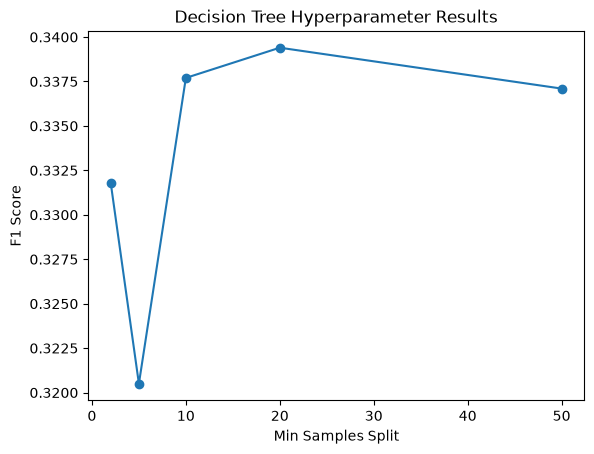

In [ ]:
#Visualize Decision Tree tuning results
plt.plot(
    dt_tuning_results['min_samples_split'],
    dt_tuning_results['f1_score'],
    marker='o'
)

plt.xlabel('Min Samples Split')
plt.ylabel('F1 Score')
plt.title('Decision Tree Hyperparameter Results')
plt.show()


### Decision Tree Tuning Results

Diffrent min_samples_split values were tested while keeping 
max_depth fixed at 20

The highest valdidation F1-score was at 0.3394
achevied with min_samples_split=20.

Increasing min_samples_split from 2 to 20 slightly improved 
The F1-score, but increassing it further to 50 reasulted in a small decrase.

### Gaussin Naive Bayes Hyperparameter tuning 

The var_smothing parameter is tested using diffrent values.
the models are evaluted using valdidation dataset.

In [ ]:
# Test diffrent var_smoothing values
for smoothing in [1e-9, 1e-7, 1e-5, 1e-3, 1e-1]:

    nb_tuned = GaussianNB(var_smoothing=smoothing)
    nb_tuned.fit(X_train, y_train)

    # Make predictions
    y_pred = nb_tuned.predict(X_validation)

    # Evaluate the model
    print(f"Var Smoothing: {smoothing}")
    print("Accuracy:", accuracy_score(y_validation, y_pred))
    print("Precision:", precision_score(y_validation, y_pred))
    print("Recall:", recall_score(y_validation, y_pred))
    print("F1 Score:", f1_score(y_validation, y_pred))
    print()

Var Smoothing: 1e-09
Accuracy: 0.8388630833886308
Precision: 0.36269786648313834
Recall: 0.498109640831758
F1 Score: 0.41975308641975306

Var Smoothing: 1e-07
Accuracy: 0.8447246184472462
Precision: 0.2417910447761194
Recall: 0.15311909262759923
F1 Score: 0.1875

Var Smoothing: 1e-05
Accuracy: 0.8641893386418934
Precision: 0.21283783783783783
Recall: 0.05954631379962193
F1 Score: 0.0930576070901034

Var Smoothing: 0.001
Accuracy: 0.87602300376023
Precision: 0.2396694214876033
Recall: 0.027410207939508508
F1 Score: 0.04919423240033927

Var Smoothing: 0.1
Accuracy: 0.8766865737668658
Precision: 0.2
Recall: 0.017958412098298678
F1 Score: 0.03295750216825672



### Gussian Naive Bayes Tuning Results 

Diffrent var_smoothing values were tested using the validation dataset.

The highest F1-score was 0.4198, achived with var_smoothing=1e-9.

Increassing var_smoothing resulted in lower recall and F1-scores. therfore, the deafult value 1e-9 is restrained.

In [ ]:
# Store Gaussian Naive Bayes tuning results

nb_tuning_results = pd.DataFrame({
        'var_smoothing': [1e-9, 1e-7, 1e-5, 1e-3, 1e-1],
        'f1_score': [
            0.4198,
            0.1875,
            0.0931,
            0.0492,
            0.0330
        ]
    })
nb_tuning_results

,var_smoothing,f1_score
0,1.000000e-09,0.4198
1,1.000000e-07,0.1875
2,1.000000e-05,0.0931
3,1.000000e-03,0.0492
4,1.000000e-01,0.0330


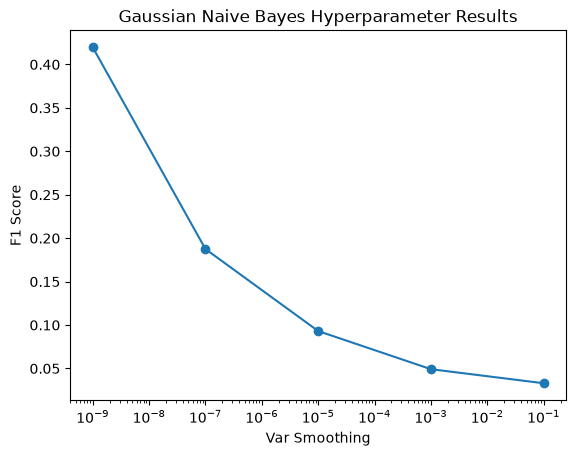

In [ ]:
# Visualize Gaussian Naive Bayes tuning results
plt.plot(
    nb_tuning_results['var_smoothing'],
    nb_tuning_results['f1_score'],
    marker='o'
)
plt.xscale('log')
plt.xlabel('Var Smoothing')
plt.ylabel('F1 Score')
plt.title('Gaussian Naive Bayes Hyperparameter Results')
plt.show()

### Gaussian Naive Bayes Tuning Conclusion

The result show that increassing var_smoothing reduces the F1-score.

The highest validation F1-score was 0.4198, achieved with var_smoothin=1e-9.

This value is restrained for the final model comparison.

### Logistic Regression Hyperparmeter Tuning 

The C parameter controls the strength of reqularization in logistic Regression.

Diffrent C values are tested to invistgate how they affect the model´s preformance.
The models are trained using scaled valdidation data.

In [ ]:
# Test diffrent C values
for c in [0.001, 0.01, 0.1, 1, 10]:

    lr_tuned = LogisticRegression(
        C=c,
        max_iter=1000,
        random_state=13
    )
    #Train the model
    lr_tuned.fit(X_train_scaled, y_train)

    # Make predictions
    y_pred = lr_tuned.predict(X_validation_scaled)

    # Evaluate the model
    print(f"C: {c}")
    print("Accuracy:", accuracy_score(y_validation, y_pred))
    print("Precision:", precision_score(y_validation, y_pred))
    print("Recall:", recall_score(y_validation, y_pred))
    print("F1 Score:", f1_score(y_validation, y_pred))
    print()

C: 0.001
Accuracy: 0.8926122539261225
Precision: 0.6761133603238867
Recall: 0.15784499054820417
F1 Score: 0.25593869731800767

C: 0.01
Accuracy: 0.893718203937182
Precision: 0.653968253968254
Recall: 0.1947069943289225
F1 Score: 0.30007283321194467

C: 0.1
Accuracy: 0.8934970139349702
Precision: 0.6479750778816199
Recall: 0.19659735349716445
F1 Score: 0.30166787527193617

C: 1
Accuracy: 0.8933864189338642
Precision: 0.6459627329192547
Recall: 0.19659735349716445
F1 Score: 0.30144927536231886

C: 10
Accuracy: 0.8933864189338642
Precision: 0.6459627329192547
Recall: 0.19659735349716445
F1 Score: 0.30144927536231886



In [ ]:
# Store Logistic Regression tuning results
lr_tuning_results = pd.DataFrame({
    'C': [0.001, 0.01, 0.1, 1, 10],
    'f1_score': [
        0.2559,
        0.3001,
        0.3017,
        0.3014,
        0.3014
    ]
})

lr_tuning_results

,C,f1_score
0,0.001,0.2559
1,0.010,0.3001
2,0.100,0.3017
3,1.000,0.3014
4,10.000,0.3014


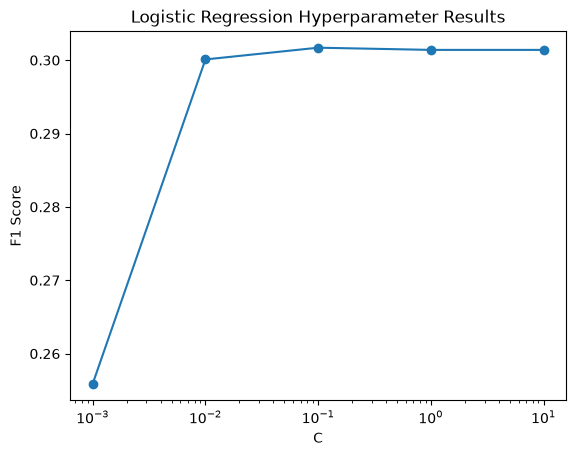

In [ ]:
# Visualize Logistic Regression tuning results

plt.plot(
    lr_tuning_results['C'],
    lr_tuning_results['f1_score'],
    marker='o'
)

plt.xscale('log')
plt.xlabel('C')
plt.ylabel('F1 Score')
plt.title('Logistic Regression Hyperparameter Results')
plt.show()

### Logistic Regression Tuning Result

Diffrent C values were tested using the valdidation dataset.

The highest F1-score was 0.3017 achived with C=0.1.

The result show the increasing C initially improves, the F1-score, but preformance remains almost unchanged for values above 0.1.

### Final Model Comparison

The three models are compared using their validation results after hypermeter tuning.

F1-score is used as the main evaluation metric beacuse the dataset has an imbalanced target variable. 

In [ ]:
# compare the tuned models

final_comparison = pd.DataFrame({
    'Model': [
        'Decision Tree',
        'Gaussian Naive Bayes',
        'Logistic Regression'
    ],
    'F1 Score': [
        0.3394,
        0.4198,
        0.3017
    ]
})

final_comparison

,Model,F1 Score
0,Decision Tree,0.3394
1,Gaussian Naive Bayes,0.4198
2,Logistic Regression,0.3017


### Model Comparison Result

Gaussian naive Bayes achived the highest validation F1-score of approximately 0.4198.

The tuned Decision Tree achieved an F1-score of 0.3394, while logistic Regression achived 0.3017.

Based on the valdation F1-Score, Gaussian naive Bayes is selected for final evaluation 

### Handling Class Imbalance

The dataset is imbalanced, with approximately 88.3% of customers answering no and 11.7% answering yes.

To investigate whether model perfromance can improved, we will test Logistic Regression using balanced 

In [ ]:
# Logistic Regression with balnced class weights

lr_balanced = LogisticRegression(
    C=0.1,
    max_iter=1000,
    class_weight='balanced',
    random_state=13
)

lr_balanced.fit(X_train_scaled, y_train)

y_pred_balanced = lr_balanced.predict(X_validation_scaled)

# Evaluate the model
print("Accuracy:", accuracy_score(y_validation, y_pred_balanced))
print("Precision:", precision_score(y_validation, y_pred_balanced))
print("Recall:", recall_score(y_validation, y_pred_balanced))
print("F1 Score:", f1_score(y_validation, y_pred_balanced))

Accuracy: 0.7517142225171423
Precision: 0.26825458805154234
Recall: 0.6493383742911153
F1 Score: 0.37966289030118816


### Balanced Logistic Regression Results

Using balanced class weights improved the F1-score from 0.3017 to 0.3797.

Recall increassed significtly, from 0.1966 to 0.6493.
However, precision and accuracy decreassed.

this shows that class weighing helped the model identify more cutomers who subscribed, but also increased the number of false postives.

In [ ]:
# Decision Tree with balanced class weights
dt_balanced = DecisionTreeClassifier(
    max_depth=20,
    min_samples_split=20,
    class_weight='balanced',
    random_state=13
)
dt_balanced.fit(X_train, y_train)
y_pred_dt_balanced = dt_balanced.predict(X_validation)

# Evaluate the model
print("Accuracy:", accuracy_score(y_validation, y_pred_dt_balanced))
print("Precision:", precision_score(y_validation, y_pred_dt_balanced))
print("Recall:", recall_score(y_validation, y_pred_dt_balanced))
print("F1 Score:", f1_score(y_validation, y_pred_dt_balanced))

Accuracy: 0.7459632824596328
Precision: 0.24369052544476624
Recall: 0.556710775047259
F1 Score: 0.3389928057553957


### Balanced with Decision Tree Result
Using balanced class weights increassed recall from 0.2647 to 0.5567. 

However, precision decressed from 0.4730 to 0.2437.

The F1-score remained approximately the same, changing from 0.3394 to 0.3390

this indicates that class weighting imporved recall, but did not improve the overall F1-score.

In [ ]:
update_comparison = pd.DataFrame({
    'Model': [
        'Decision Tree',
        'Gaussian Naive Bayes',
        'Logistic Regression',
        'Logistic Regression (Balanced)',
        'Decision Tree (Balanced)'
    ],
    'F1 Score': [
        0.3394,
        0.4198,
        0.3017,
        0.3797,
        0.3390
    ]
})

update_comparison

,Model,F1 Score
0,Decision Tree,0.3394
1,Gaussian Naive Bayes,0.4198
2,Logistic Regression,0.3017
3,Logistic Regression (Balanced),0.3797
4,Decision Tree (Balanced),0.3390


### Final Model testing 

Gassian naive Bayes model was the best performing model,bescuse it achived the highest F1-score on the valdation dataset.

The selceted model will now be evaluted on the previously unseen test dataset.

The evaluation includes accuracy, precision, recall and F1-score.

In [ ]:
# Final Gaussian Naive Bayes model
final_model = GaussianNB(var_smoothing=1e-9)

# Train the model
final_model.fit(X_train, y_train)

#Predict on the test data
y_test_pred = final_model.predict(X_test)

# Evaluate the model 
print("Accuracy:", accuracy_score(y_test, y_test_pred))
print("Precision:", precision_score(y_test, y_test_pred))
print("Recall:", recall_score(y_test, y_test_pred))
print("F1 Score:", f1_score(y_test, y_test_pred))

Accuracy: 0.8445206236868296
Precision: 0.3665644171779141
Recall: 0.45179584120982985
F1 Score: 0.40474174428450466


### Final Test Result 

The Gaussian Naive Bayes model achieved an accuracy of 0.8445 and an F1-score of 0.4047 on the test dataset.

The test F1-score was slightly lower than the validation F1-score of 0.4198

The model achieved a recall of 0.4518, meaning it correctly identified almost 45.18% of customer who subcribed

## Confusion Matrix 

A confusion matrix is used to visualize the preformance of the final Gaussian Naive Bayes model. 

it shows the number of correct and inorrect prediction for both classes.

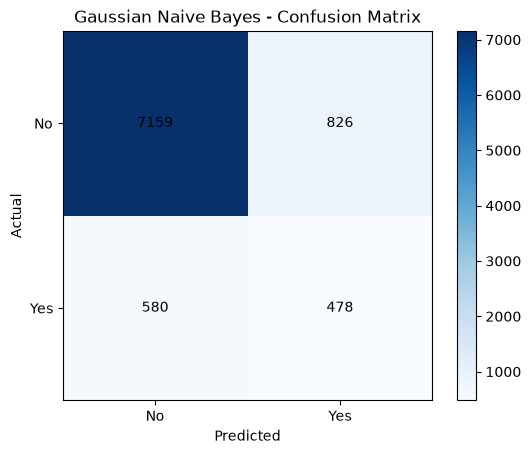

In [ ]:
# Create a confusion matrix
cm = confusion_matrix(y_test, y_test_pred)

# Display the confusion matrix
plt.imshow(cm, cmap='Blues')
plt.colorbar()

plt.xticks([0, 1], ['No', 'Yes'])
plt.yticks([0, 1], ['No', 'Yes'])

plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Gaussian Naive Bayes - Confusion Matrix')

# Diplay the counts in the confusion matrix
for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i, j], ha='center', va='center')

plt.show()

### Confusion Matrix Results

The confusion matrix shows that the Gaussian Naive Bayes model correctly classified 7159 customers who did not subscribe and 478 customers who subscribed.

However, the model incorrectly classified 826 customer as subscribers and faild to identify 580 customers who actually subscribed.

The model achived a recall of approximately 45.18% indicating that it identified fewer than half of the customers who subcribed

## Conclusion 
 
in this project, three machine learning models were trained and evaluted using Bank Marketing dataset:
Decision tree, Gaussian Naive Bayes and logistic Regression.

Hyperparmeter tuning was preformed to improve model preformance. Class balancing was also investigated for decision Tree and logistic Regression.

Guassian Naive Bayes achived the highest validation F1-score of 0.4198 and was selcted for final testing.

on the test dataset, the model achived:
- Accuracy: 0.8445 
- Precision: 0.3666
- Recall: 0.4518
- F1-score: 0.4047

The results show that the model correctly identified approximetly 45% of customers who subscribed.

Although the model achived relatively high accuracy, its ability to idenitfy subscribers was limited.

Future improvements could include additional hyperparmeter tuning and testing other models.